# International Debt Analysis System
**Steps 1-3: Data Collection, Cleaning and EDA (Python)**

Dataset: World Bank International Debt Statistics (IDS_ALLCountries_Data.csv)

## Step 1: Data Collection
Load the CSV into a pandas DataFrame and look at its structure.

In [1]:
import pandas as pd

# encoding="latin1" avoids the UnicodeDecodeError caused by a special character in the file
df = pd.read_csv("IDS_ALLCountries_Data.csv", encoding="latin1")

print(df.shape)
print(df.head())
print(df.info())

(62983, 39)
  Country Name Country Code Counterpart-Area Name Counterpart-Area Code  \
0  Afghanistan   AFG                        World                   WLD   
1  Afghanistan   AFG                        World                   WLD   
2  Afghanistan   AFG                        World                   WLD   
3  Afghanistan   AFG                        World                   WLD   
4  Afghanistan   AFG                        World                   WLD   

                                         Series Name  Series Code  2000  2001  \
0  Average grace period on new external debt comm...  DT.GPA.DPPG   NaN   NaN   
1  Average grace period on new external debt comm...  DT.GPA.OFFT   NaN   NaN   
2  Average grace period on new external debt comm...  DT.GPA.PRVT   NaN   NaN   
3  Average grant element on new external debt com...  DT.GRE.DPPG   NaN   NaN   
4  Average grant element on new external debt com...  DT.GRE.OFFT   NaN   NaN   

   2002  2003  ...  2023  2024  2025  2026  2027  

## Step 2: Data Cleaning
### 2.1 Check missing values and duplicates

In [2]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

Country Name                 3
Country Code                 5
Counterpart-Area Name        5
Counterpart-Area Code        5
Series Name                  5
Series Code                  5
2000                     13493
2001                     13549
2002                     13721
2003                     13982
2004                     13788
2005                     13846
2006                     13589
2007                     13338
2008                     13486
2009                     13215
2010                     13222
2011                     13903
2012                     13975
2013                     13604
2014                     12479
2015                     12552
2016                     12791
2017                     12650
2018                     12687
2019                     12490
2020                     12027
2021                     12256
2022                     12262
2023                     12342
2024                     12393
2025                     50128
2026    

In [3]:
# The last rows of the file are empty rows and footer text, not real data
df.tail(8)

,Country Name,Country Code,Counterpart-Area Name,Counterpart-Area Code,Series Name,Series Code,2000,2001,2002,2003,...,2023,2024,2025,2026,2027,2028,2029,2030,2031,2032
62975,Zimbabwe,ZWE,World,WLD,"Undisbursed external debt, total (UND, current...",DT.UND.DPPG.CD,1.043005e+09,742345186.0,495159055.8,507424047.1,...,7.713904e+08,6.944589e+08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
62976,Zimbabwe,ZWE,World,WLD,"Use of IMF credit (DOD, current US$)",DT.DOD.DIMF.US.CD,2.806598e+08,261951544.4,280246014.7,301553836.0,...,0.000000e+00,0.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
62977,Zimbabwe,ZWE,World,WLD,"Use of IMF credit and SDR allocations (DOD, cu...",DT.DOD.DIMF.CD,2.939495e+08,274770190.4,294113118.7,316710730.0,...,1.363159e+09,1.325023e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
62978,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
62979,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
62980,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
62981,Data from database: International Debt Statistics,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
62982,Last Updated: 12/03/2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.2 Remove junk rows
Real rows always have a Country Code. Rows without it are empty or footer rows.

In [4]:
df = df.dropna(subset=["Country Code"])
print(df.shape)
print("Duplicates left:", df.duplicated().sum())

(62978, 39)
Duplicates left: 0


### 2.3 Remove rows with no value in any year (2000-2024)

In [5]:
year_cols = [str(y) for y in range(2000, 2025)]

# Rows where ALL year values are empty
print(df[year_cols].isnull().all(axis=1).sum())

# ~ means NOT, so we keep rows that have at least one value
df = df[~df[year_cols].isnull().all(axis=1)]
print(df.shape)

3480
(59498, 39)


### 2.4 Drop the future years (2025-2032)
These columns are mostly empty projections.

In [6]:
future_cols = [str(y) for y in range(2025, 2033)]
df = df.drop(columns=future_cols)
print(df.shape)

(59498, 31)


### 2.5 Rename columns
Simple names without spaces or hyphens, ready for MySQL.

In [7]:
df = df.rename(columns={
    "Country Name": "country_name",
    "Country Code": "country_code",
    "Counterpart-Area Name": "counterpart_area_name",
    "Counterpart-Area Code": "counterpart_area_code",
    "Series Name": "series_name",
    "Series Code": "series_code"
})
df.columns

Index(['country_name', 'country_code', 'counterpart_area_name',
       'counterpart_area_code', 'series_name', 'series_code', '2000', '2001',
       '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010',
       '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019',
       '2020', '2021', '2022', '2023', '2024'],
      dtype='object')

### 2.6 Remove World Bank groups (not countries)
Groups like "South Asia" or "Low income" are sums of many countries. Keeping them would count debt twice.

In [8]:
print(df["country_name"].nunique(), "names before removing groups")

groups = [
    "East Asia & Pacific (excluding high income)",
    "Europe & Central Asia (excluding high income)",
    "IDA only",
    "IDA total",
    "Latin America & Caribbean (excluding high income)",
    "Least developed countries: UN classification",
    "Low & middle income",
    "Low income",
    "Lower middle income",
    "Middle East, North Africa, Afghanistan & Pakistan (excluding high income)",
    "Middle income",
    "South Asia",
    "Sub-Saharan Africa (excluding high income)",
    "Upper middle income"
]

df_groups = df[df["country_name"].isin(groups)]   # kept separately, nothing is lost
df = df[~df["country_name"].isin(groups)]         # real countries only

print(df["country_name"].nunique(), "countries after removing groups")
print(df.shape)

134 names before removing groups
120 countries after removing groups
(51620, 31)


### 2.7 Save the cleaned data

In [9]:
df.to_csv("cleaned_debt_data_v2.csv", index=False)

## Step 3: Exploratory Data Analysis (EDA)
### 3.1 Understand the data

In [10]:
print("Countries:", df["country_name"].nunique())
print("Debt types (series):", df["series_name"].nunique())

Countries: 120
Debt types (series): 576


In [11]:
# Series metadata file explains the unit and definition of each series
series_meta = pd.read_csv("IDS_SeriesMetaData.csv", encoding="latin1")
series_meta.head()

,Code,License Type,Indicator Name,Short definition,Long definition,Source,Topic,Dataset,Periodicity,Aggregation method,Limitations and exceptions,General comments
0,DT.GPA.DPPG,NaN,Average grace period on new external debt comm...,Grace period is the period from the date of si...,Grace period is the period from the date of si...,"World Bank, International Debt Statistics.",Economic Policy & Debt: External debt: Terms,International Debt Statistics,Annual,Weighted average,NaN,NaN
1,DT.GPA.OFFT,NaN,Average grace period on new external debt comm...,Grace period is the period from the date of si...,Grace period is the period from the date of si...,"World Bank, International Debt Statistics.",Economic Policy & Debt: External debt: Terms,International Debt Statistics,Annual,Weighted average,NaN,NaN
2,DT.GPA.PRVT,NaN,Average grace period on new external debt comm...,Grace period is the period from the date of si...,Grace period is the period from the date of si...,"World Bank, International Debt Statistics.",Economic Policy & Debt: External debt: Terms,International Debt Statistics,Annual,Weighted average,NaN,NaN
3,DT.GRE.DPPG,NaN,Average grant element on new external debt com...,The grant element of a loan is the grant equiv...,The grant element of a loan is the grant equiv...,"World Bank, International Debt Statistics.",Economic Policy & Debt: External debt: Terms,International Debt Statistics,Annual,Weighted average,NaN,NaN
4,DT.GRE.OFFT,NaN,Average grant element on new external debt com...,The grant element of a loan is the grant equiv...,The grant element of a loan is the grant equiv...,"World Bank, International Debt Statistics.",Economic Policy & Debt: External debt: Terms,International Debt Statistics,Annual,Weighted average,NaN,NaN


### 3.2 Keep only money (US$) rows
Some series are percentages or years, so they cannot be added with dollar values.

In [12]:
usd = df["series_name"].str.contains("current US$", regex=False)
df_usd = df[usd]
print(df_usd.shape)

(47101, 31)


### 3.3 Main series for ranking countries
"External debt stocks, total" is the headline figure. Other series overlap with it, so we do not add them together.

In [13]:
total_debt = df_usd[df_usd["series_name"].str.contains("External debt stocks, total", regex=False)]
print(total_debt.shape)   # one row per country

(120, 31)


### 3.4 Top 10 and bottom 10 countries (2024)

In [14]:
top10 = total_debt[["country_name", "2024"]].sort_values("2024", ascending=False).head(10)
top10

,country_name,2024
10503,China,2.420000e+12
25632,India,7.160000e+11
7009,Brazil,6.050000e+11
37673,Mexico,5.910000e+11
57776,Turkiye,5.150000e+11
26173,Indonesia,4.210000e+11
1940,Argentina,2.420000e+11
11050,Colombia,2.020000e+11
59272,Ukraine,1.930000e+11
55648,Thailand,1.920000e+11


In [15]:
bottom10 = total_debt[["country_name", "2024"]].dropna().sort_values("2024").head(10)
bottom10

,country_name,2024
56845,Tonga,173176112.1
56097,Timor-Leste,296673869.1
48049,Sao Tome and Principe,326406625.8
11538,Comoros,385570286.6
47614,Samoa,394938377.5
60816,Vanuatu,519876544.1
13678,Dominica,569530343.0
49870,Solomon Islands,596145038.0
17074,Eritrea,667267678.5
52570,St. Vincent and the Grenadines,806447451.4


### 3.5 Charts

In [16]:
import os
import matplotlib.pyplot as plt

os.makedirs("charts", exist_ok=True)   # folder to save the pictures

**Chart 1: Top 10 countries by external debt**

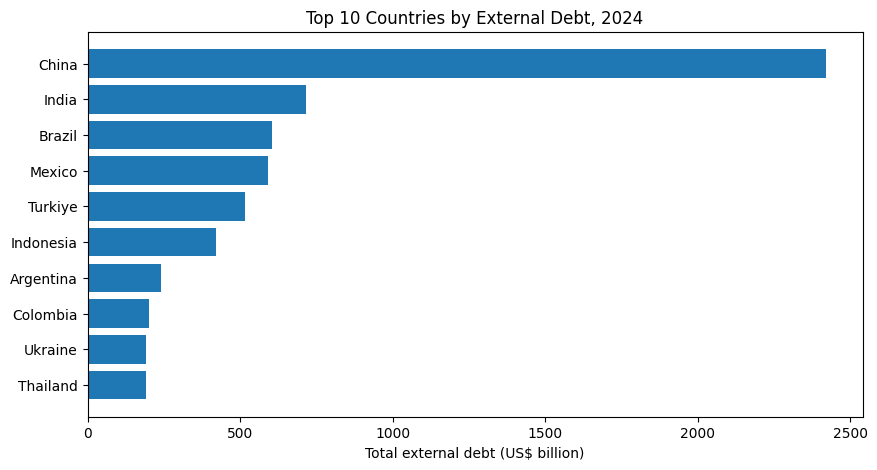

In [17]:
plt.figure(figsize=(10, 5))
plt.barh(top10["country_name"], top10["2024"] / 1e9)
plt.xlabel("Total external debt (US$ billion)")
plt.title("Top 10 Countries by External Debt, 2024")
plt.gca().invert_yaxis()
plt.savefig("charts/01_top10_countries.png", bbox_inches="tight")
plt.show()

**Chart 2: Bottom 10 countries by external debt**

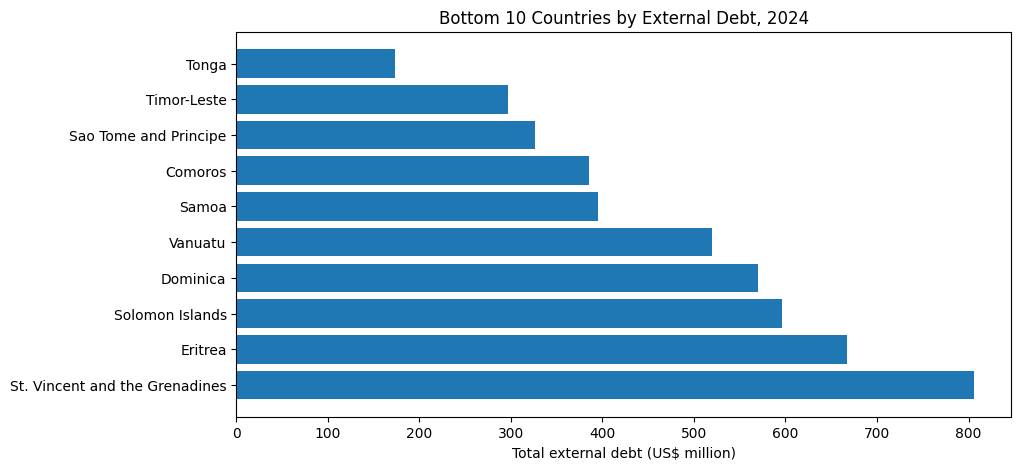

In [18]:
plt.figure(figsize=(10, 5))
plt.barh(bottom10["country_name"], bottom10["2024"] / 1e6)
plt.xlabel("Total external debt (US$ million)")
plt.title("Bottom 10 Countries by External Debt, 2024")
plt.gca().invert_yaxis()
plt.savefig("charts/02_bottom10_countries.png", bbox_inches="tight")
plt.show()

**Chart 3: Biggest debt types (indicators)**

In [19]:
# Keep only debt series
debt_only = df_usd[df_usd["series_name"].str.contains("external debt stocks", case=False, regex=False)]

series_total = debt_only.groupby("series_name")["2024"].sum().sort_values(ascending=False).head(10)
series_total

,2024
series_name,
"External debt stocks, total (DOD, current US$)",8.939921e+12
"External debt stocks, long-term (DOD, current US$)",6.177947e+12
"External debt stocks, variable rate (DOD, current US$)",3.779022e+12
"External debt stocks, public and publicly guaranteed (PPG) (DOD, current US$)",3.560992e+12
"External debt stocks, long-term public sector (DOD, current US$)",3.533991e+12
"External debt stocks, public sector (PPG) (DOD, current US$)",3.532667e+12
"External debt stocks, general government sector (PPG) (DOD, current US$)",2.662352e+12
"External debt stocks, long-term private sector (DOD, current US$)",2.638373e+12
"External debt stocks, private nonguaranteed (PNG) (DOD, current US$)",2.612903e+12


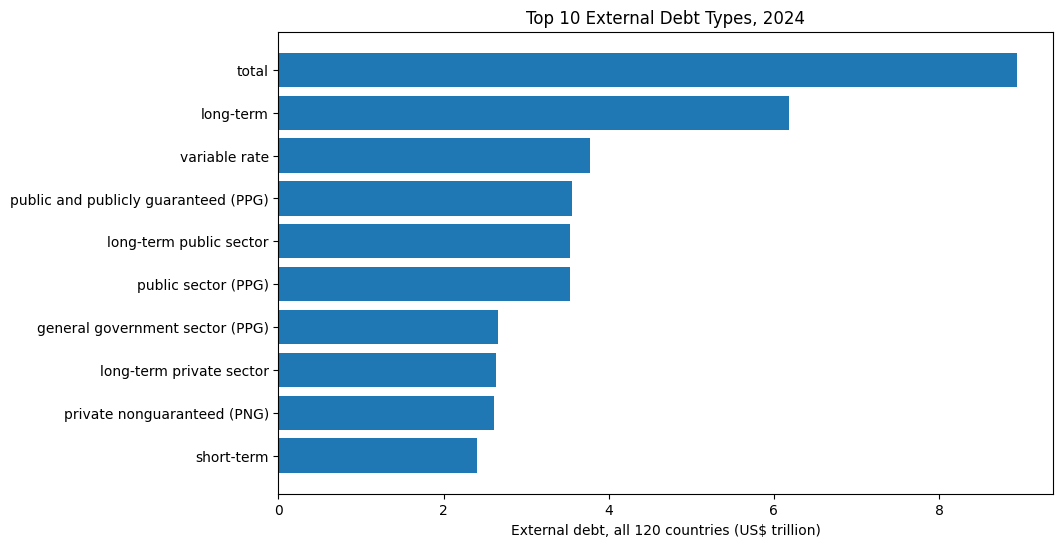

In [20]:
# Shorten the long names for the chart
labels = series_total.index.str.replace("External debt stocks, ", "", regex=False)
labels = labels.str.replace(" (DOD, current US$)", "", regex=False)

plt.figure(figsize=(10, 6))
plt.barh(labels, series_total.values / 1e12)
plt.xlabel("External debt, all 120 countries (US$ trillion)")
plt.title("Top 10 External Debt Types, 2024")
plt.gca().invert_yaxis()
plt.savefig("charts/03_debt_types.png", bbox_inches="tight")
plt.show()

**Chart 4: Total debt trend (2000-2024)**

In [21]:
yearly = total_debt[year_cols].sum()   # one total per year
yearly

,0
2000,1.832122e+12
2001,1.860674e+12
2002,1.913528e+12
2003,2.064561e+12
2004,2.188005e+12
2005,2.160938e+12
2006,2.305563e+12
2007,2.686316e+12
2008,2.888668e+12
2009,3.146071e+12


In [22]:
# How many times bigger is 2024 than 2000?
yearly["2024"] / yearly["2000"]

np.float64(4.879543592174645)

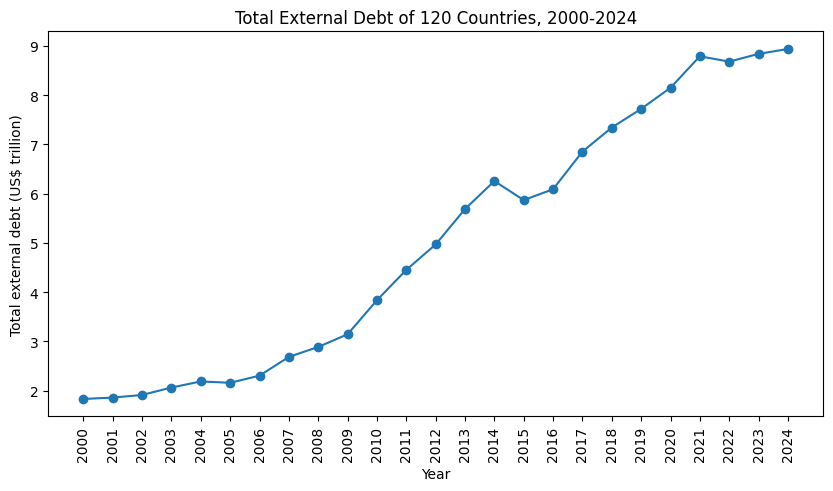

In [23]:
plt.figure(figsize=(10, 5))
plt.plot(yearly.index, yearly.values / 1e12, marker="o")
plt.xlabel("Year")
plt.ylabel("Total external debt (US$ trillion)")
plt.title("Total External Debt of 120 Countries, 2000-2024")
plt.xticks(rotation=90)
plt.savefig("charts/04_yearly_trend.png", bbox_inches="tight")
plt.show()

**Chart 5: Trend of the top 5 countries**

In [24]:
top5_names = top10["country_name"].head(5)
top5 = total_debt[total_debt["country_name"].isin(top5_names)]
top5 = top5.set_index("country_name")[year_cols]
top5

,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
country_name,,,,,,,,,,,,,,,,,,,,,
Brazil,2.430000e+11,2.300000e+11,2.320000e+11,2.360000e+11,2.210000e+11,1.880000e+11,1.940000e+11,2.380000e+11,2.630000e+11,2.820000e+11,...,5.430000e+11,5.430000e+11,5.430000e+11,5.580000e+11,5.690000e+11,5.490000e+11,5.710000e+11,5.790000e+11,6.070000e+11,6.050000e+11
China,1.460000e+11,1.840000e+11,1.850000e+11,2.070000e+11,2.470000e+11,2.860000e+11,3.260000e+11,3.780000e+11,3.860000e+11,4.540000e+11,...,1.330000e+12,1.410000e+12,1.710000e+12,1.960000e+12,2.110000e+12,2.330000e+12,2.720000e+12,2.530000e+12,2.450000e+12,2.420000e+12
India,1.010000e+11,9.950009e+10,1.060000e+11,1.190000e+11,1.240000e+11,1.210000e+11,1.600000e+11,2.040000e+11,2.270000e+11,2.560000e+11,...,4.790000e+11,4.560000e+11,5.120000e+11,5.210000e+11,5.610000e+11,5.650000e+11,6.120000e+11,6.160000e+11,6.480000e+11,7.160000e+11
Mexico,1.780000e+11,2.030000e+11,1.930000e+11,1.990000e+11,2.100000e+11,2.180000e+11,2.220000e+11,2.510000e+11,2.480000e+11,2.510000e+11,...,5.380000e+11,5.450000e+11,5.790000e+11,6.020000e+11,6.170000e+11,6.170000e+11,6.010000e+11,5.860000e+11,5.960000e+11,5.910000e+11
Turkiye,1.170000e+11,1.130000e+11,1.320000e+11,1.480000e+11,1.650000e+11,1.780000e+11,2.180000e+11,2.690000e+11,2.940000e+11,2.860000e+11,...,3.990000e+11,3.990000e+11,4.470000e+11,4.260000e+11,4.140000e+11,4.290000e+11,4.350000e+11,4.560000e+11,5.000000e+11,5.150000e+11


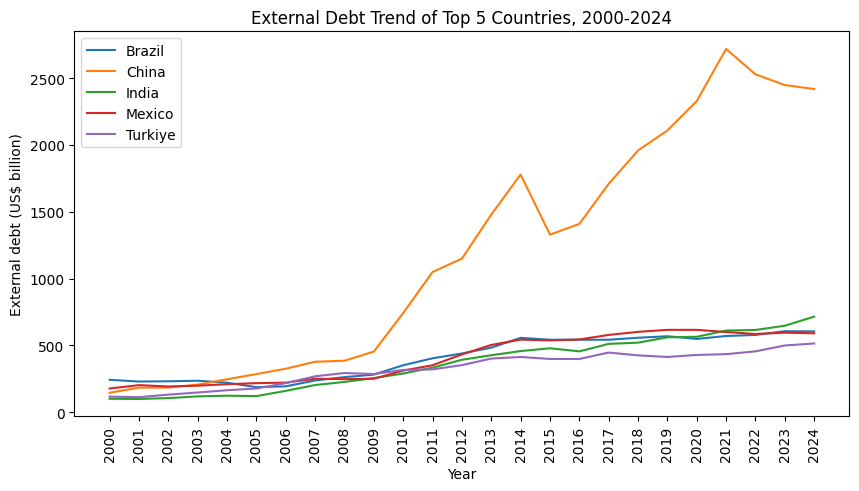

In [25]:
plt.figure(figsize=(10, 5))
for country in top5.index:   # one line per country
    plt.plot(top5.columns, top5.loc[country] / 1e9, label=country)
plt.xlabel("Year")
plt.ylabel("External debt (US$ billion)")
plt.title("External Debt Trend of Top 5 Countries, 2000-2024")
plt.legend()
plt.xticks(rotation=90)
plt.savefig("charts/05_top5_countries_trend.png", bbox_inches="tight")
plt.show()

**Chart 6: Distribution of debt across countries (2024)**

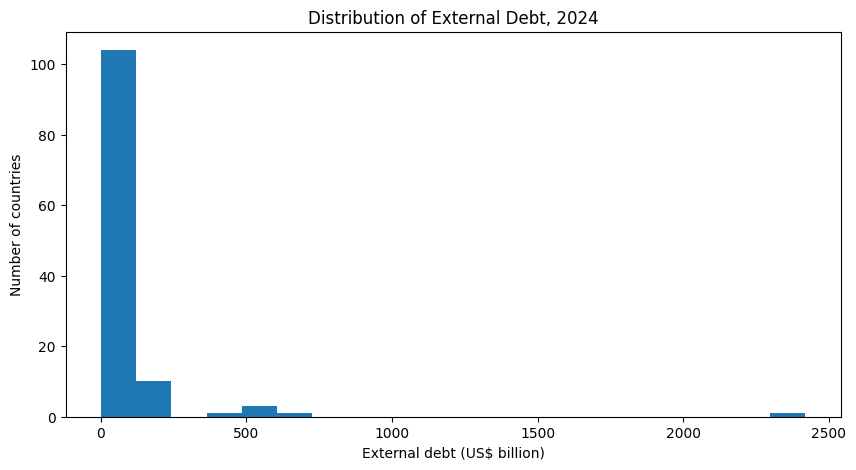

In [26]:
debt_2024 = total_debt["2024"].dropna() / 1e9

plt.figure(figsize=(10, 5))
plt.hist(debt_2024, bins=20)
plt.xlabel("External debt (US$ billion)")
plt.ylabel("Number of countries")
plt.title("Distribution of External Debt, 2024")
plt.savefig("charts/06_debt_distribution.png", bbox_inches="tight")
plt.show()

### 3.6 Summary statistics (2024)

In [27]:
total_debt["2024"].describe()

,2024
count,1.200000e+02
mean,7.449934e+10
std,2.470678e+11
min,1.731761e+08
25%,3.417751e+09
50%,1.284569e+10
75%,4.390611e+10
max,2.420000e+12
